Câu a): Đọc dữ liệu, xóa dòng trống, đổi tên cột

In [2]:
print("Lê Anh Pha - 6451071056")

data = pd.read_csv('heart.csv', na_values='?')
print(data.head())
print("Trước khi xóa:", data.shape)      # thường là (303, 14) hoặc (1025, 14)

data = data.dropna()
print("Sau khi xóa dòng trống:", data.shape)

data.columns = ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
                'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
                'exercise_induced_angina', 'st_depression', 'st_slope',
                'num_major_vessels', 'thalassemia', 'target']

print(data['target'].unique())           # kỳ vọng [0 1] hoặc [1 0]
data['target'] = (data['target'] > 0).astype(int)
print(data['target'].value_counts())
data.info()

Lê Anh Pha - 6451071056
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0     2       1  
4   0     2       1  
Trước khi xóa: (303, 14)
Sau khi xóa dòng trống: (303, 14)
[1 0]
target
1    165
0    138
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                    

Câu 3: Pearson

Lê Anh Pha - 6451071056


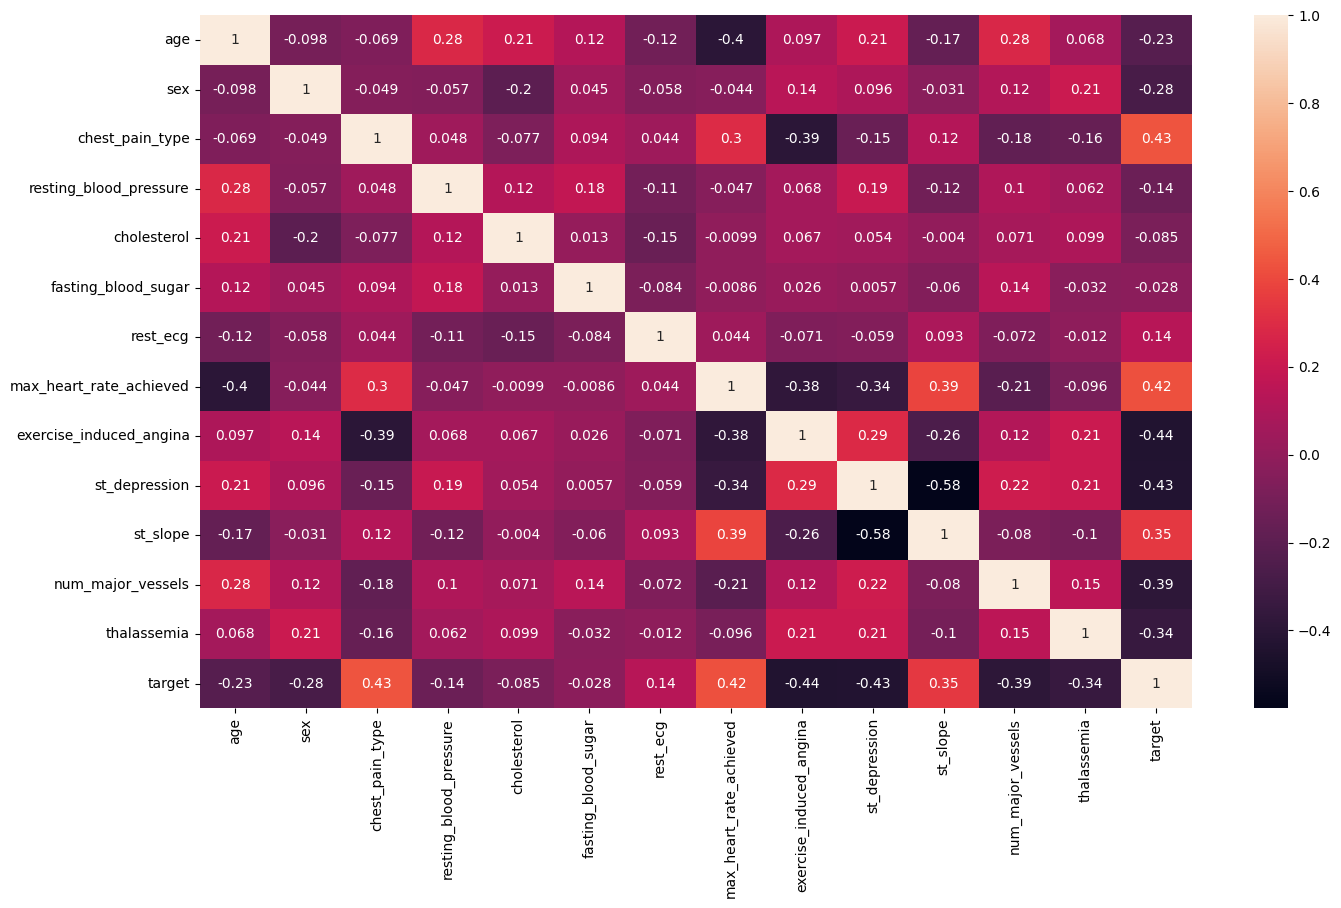

In [3]:
print("Lê Anh Pha - 6451071056")

plt.figure(figsize=(16, 9))
sns.heatmap(data.corr(method='pearson'), annot=True)
plt.show()
# Nhận xét: nếu không có cặp thuộc tính nào tương đồng rất cao (> 0.8) thì không cần loại cột nào.

Câu 4: Tách thuộc tính và nhãn

In [4]:
print("Lê Anh Pha - 6451071056")

features = data.drop('target', axis=1)
labels = data['target']
print(features.shape, labels.shape)

Lê Anh Pha - 6451071056
(303, 13) (303,)


Câu 5: One-hot

In [5]:
print("Lê Anh Pha - 6451071056")

cat_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Cột không phải số:", list(cat_cols))      # rỗng: tất cả cột đều là số

features_onehot = pd.get_dummies(features, columns=cat_cols)
print(features_onehot.shape)

Lê Anh Pha - 6451071056
Cột không phải số: []
(303, 13)


Câu 6: Chia 70% huấn luyện, 30% kiểm thử

In [6]:
print("Lê Anh Pha - 6451071056")

X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape)

Lê Anh Pha - 6451071056
(212, 13) (91, 13)


Câu 7: Cây ID3

Lê Anh Pha - 6451071056
Accuracy: 0.7252747252747253
Report:
               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



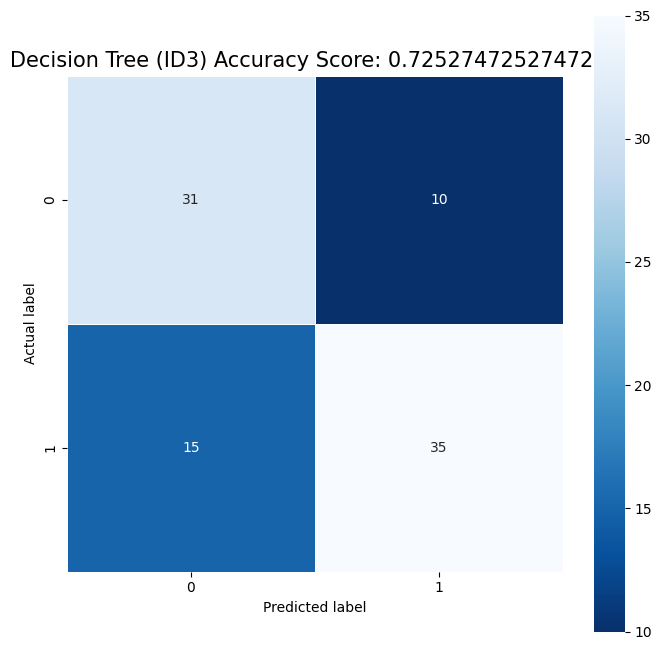

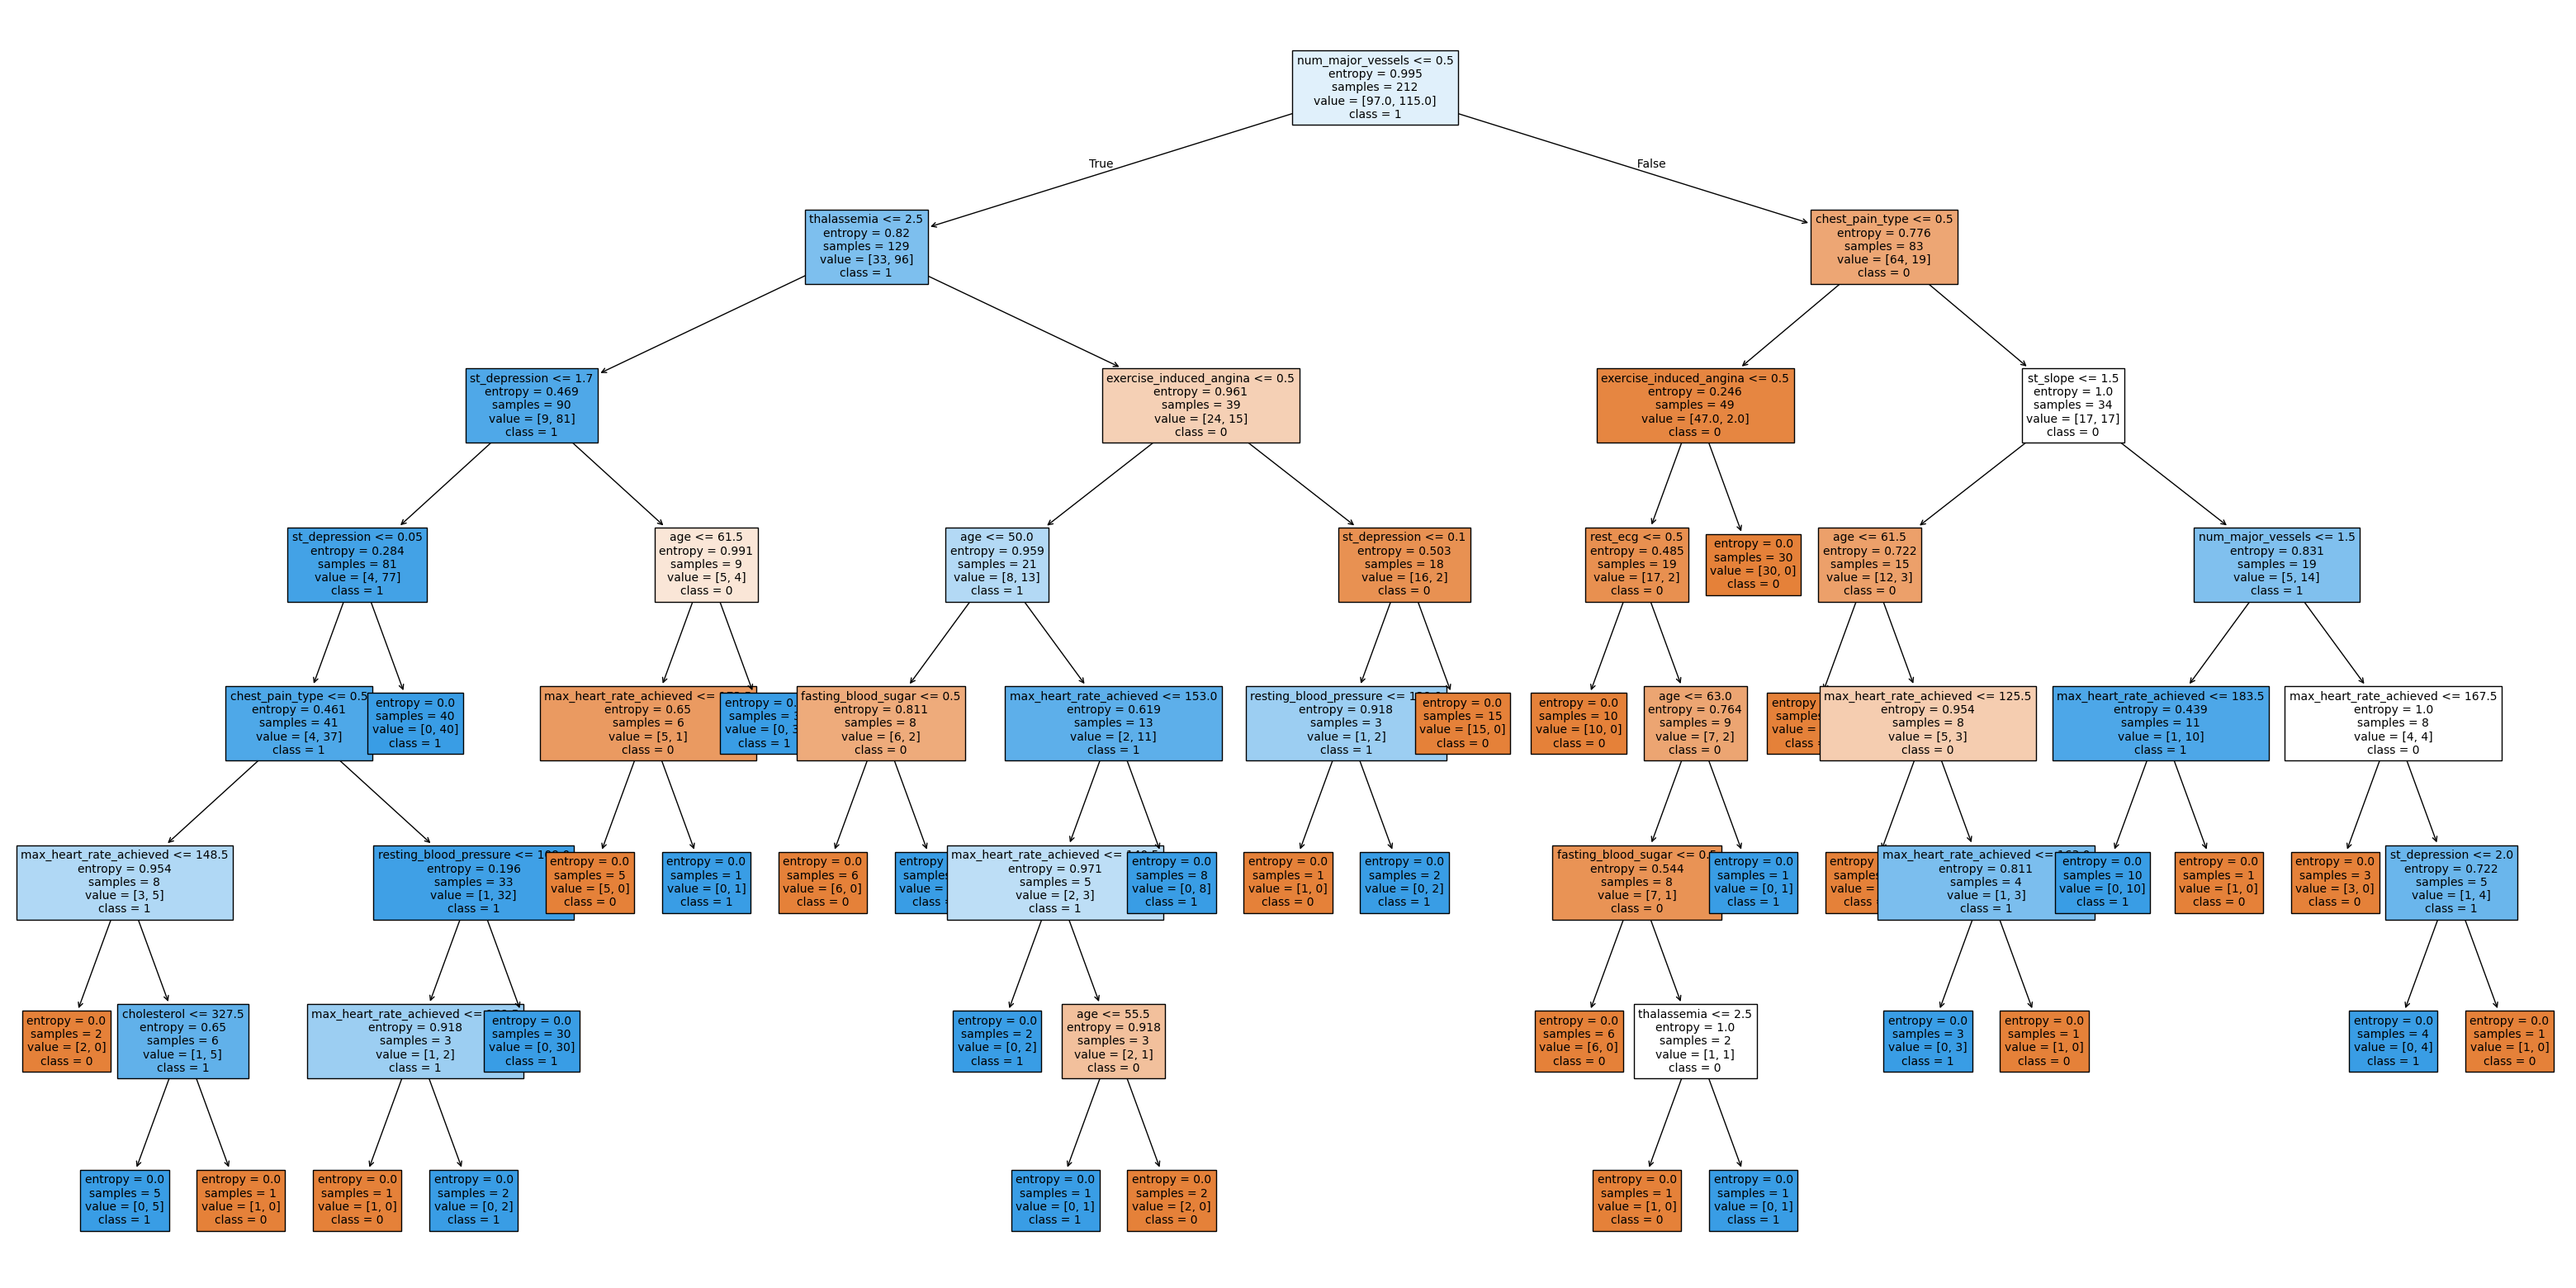

In [7]:
print("Lê Anh Pha - 6451071056")

clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf.fit(X_train, y_train)

tree_pred = clf.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:\n", metrics.classification_report(y_test, tree_pred, zero_division=0))

tree_cm = metrics.confusion_matrix(y_test, tree_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(tree_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (ID3) Accuracy Score: {0}'.format(tree_score), size=15)
plt.show()

fig, ax = plt.subplots(figsize=(40, 20))
tree.plot_tree(clf, filled=True, fontsize=10, feature_names=X_train.columns, class_names=['0', '1'])
plt.savefig('decision_tree_id3', dpi=100)
plt.show()

Câu 8: Cây CART

Lê Anh Pha - 6451071056
Accuracy: 0.7252747252747253
Report:
               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



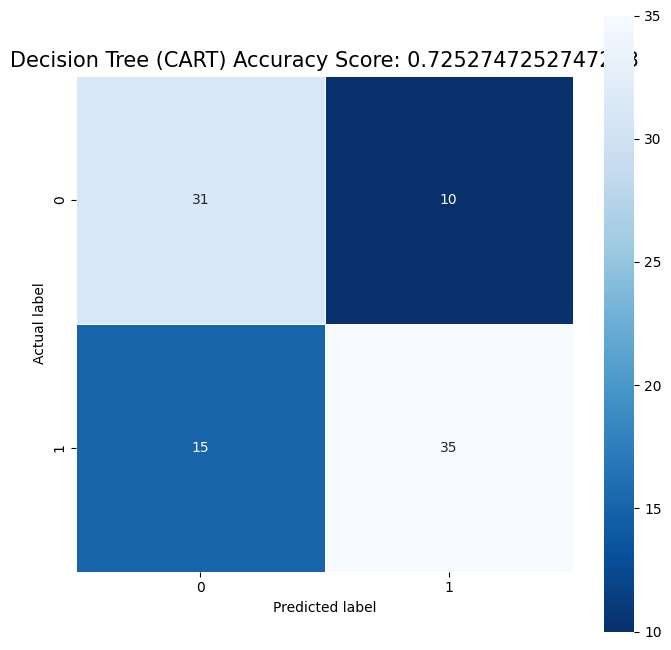

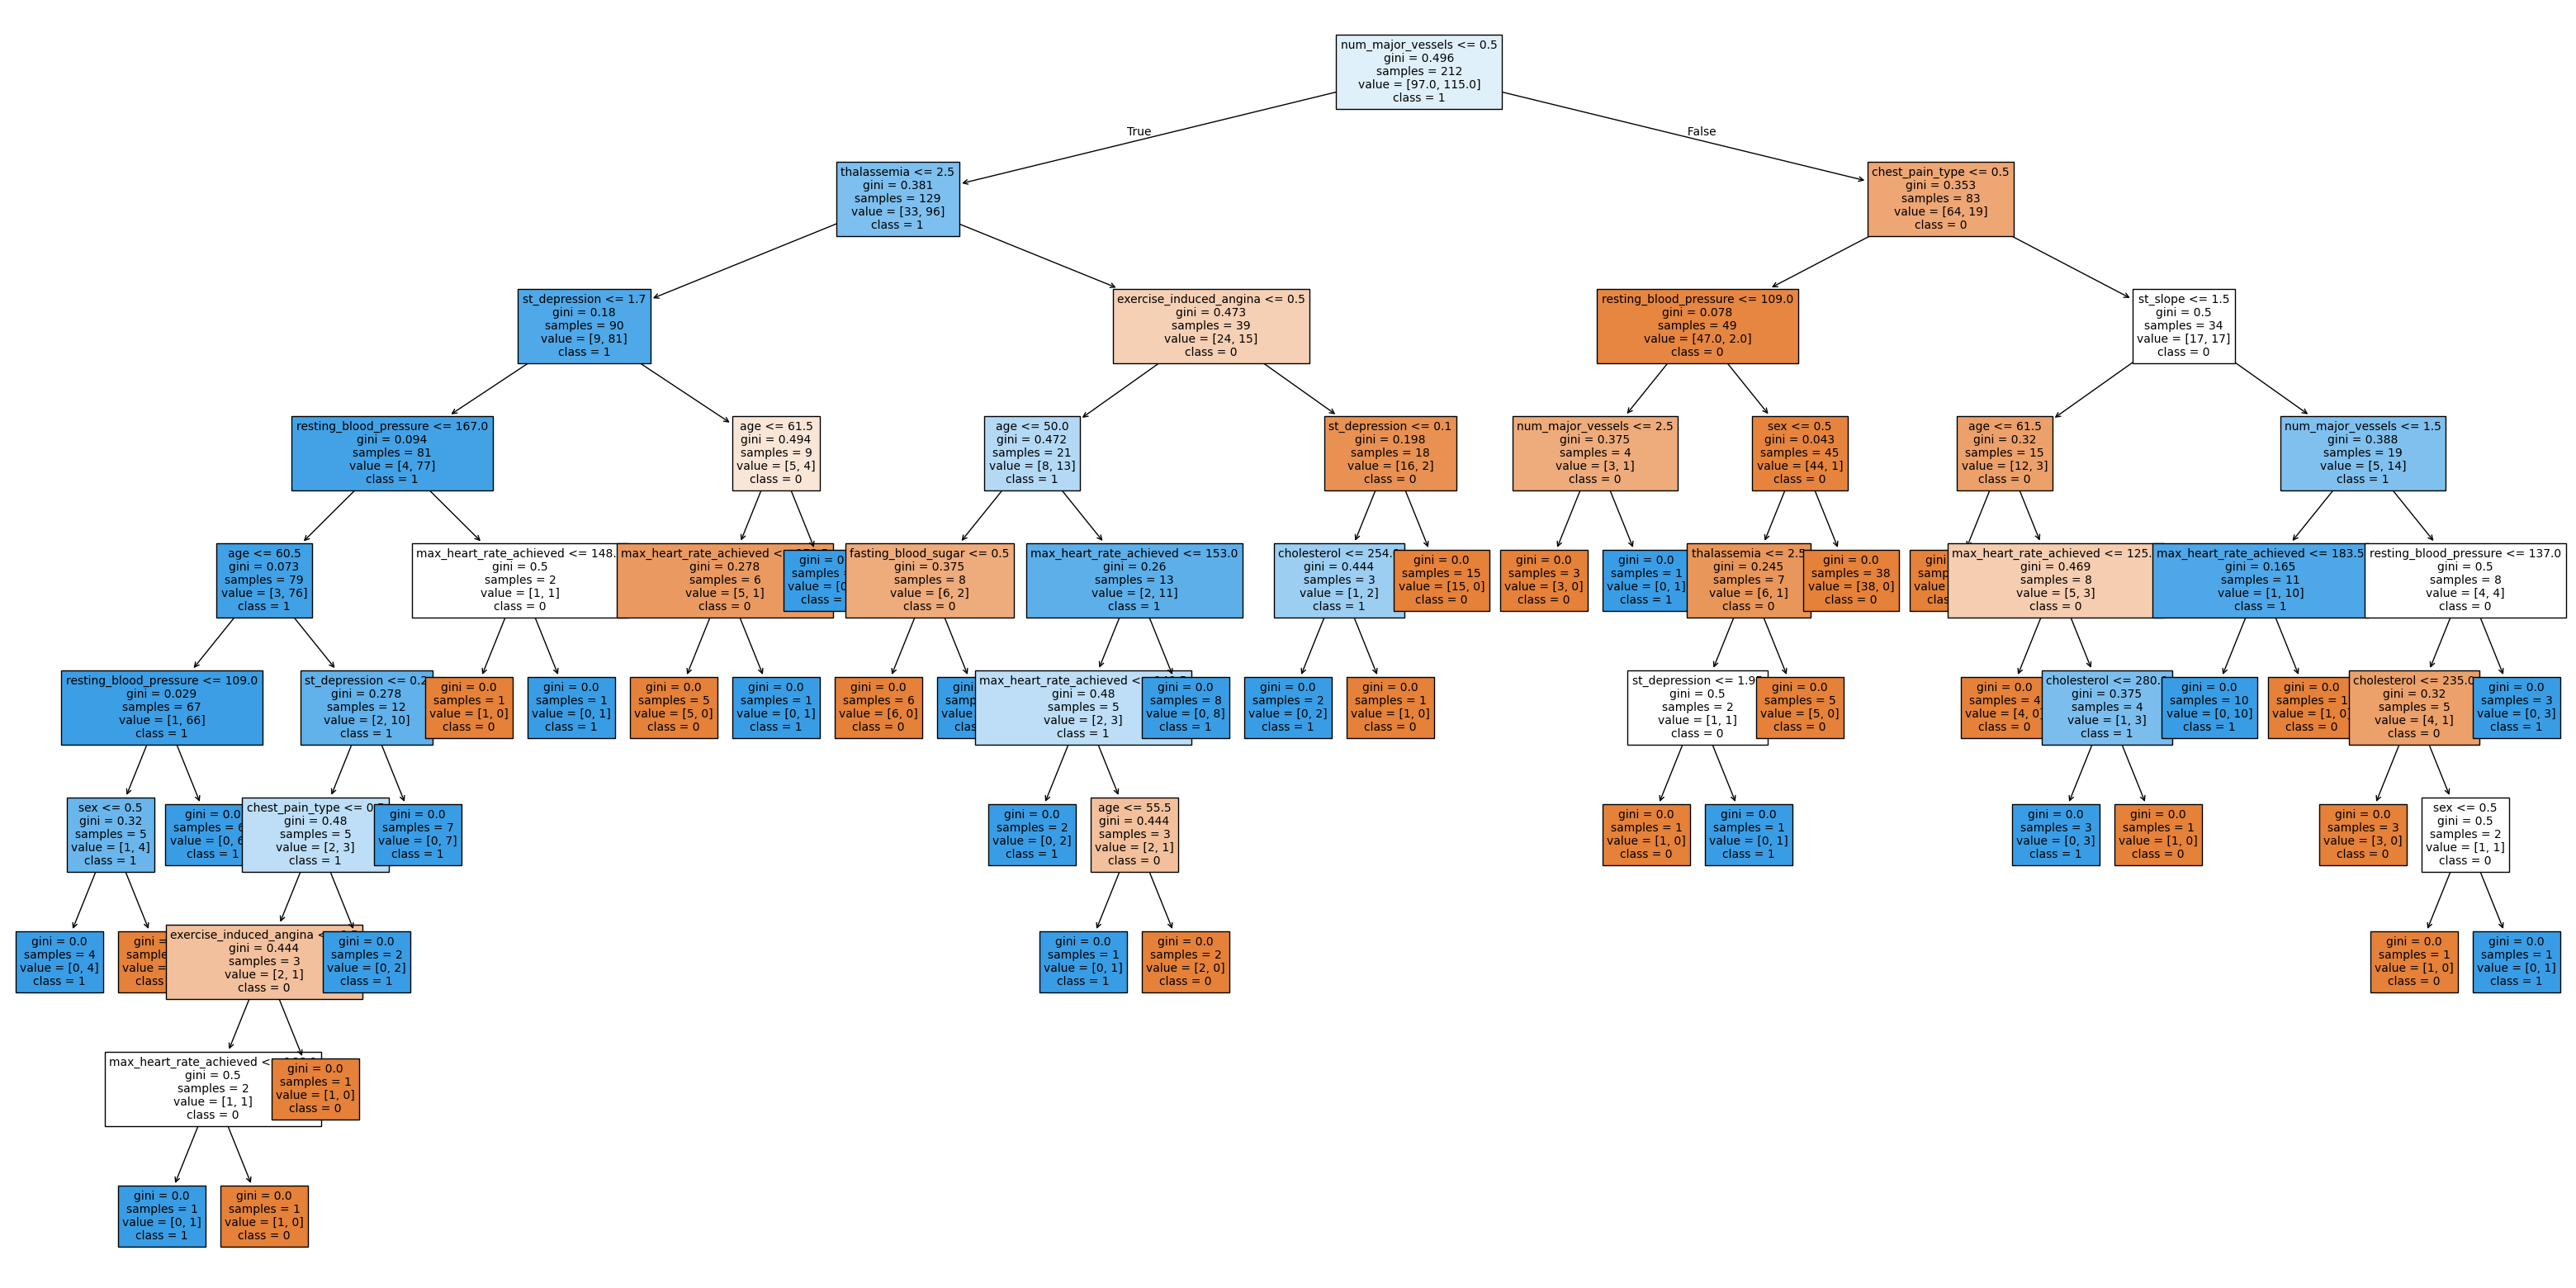

In [8]:
print("Lê Anh Pha - 6451071056")

clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:\n", metrics.classification_report(y_test, cart_pred, zero_division=0))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (CART) Accuracy Score: {0}'.format(cart_score), size=15)
plt.show()

fig, ax = plt.subplots(figsize=(40, 20))
tree.plot_tree(clf_cart, filled=True, fontsize=10, feature_names=X_train.columns, class_names=['0', '1'])
plt.savefig('decision_tree_cart', dpi=100)
plt.show()

Câu 9: Naive Bayes

Lê Anh Pha - 6451071056
Accuracy: 0.8351648351648352
Report:
               precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.89      0.80      0.84        50

    accuracy                           0.84        91
   macro avg       0.84      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91



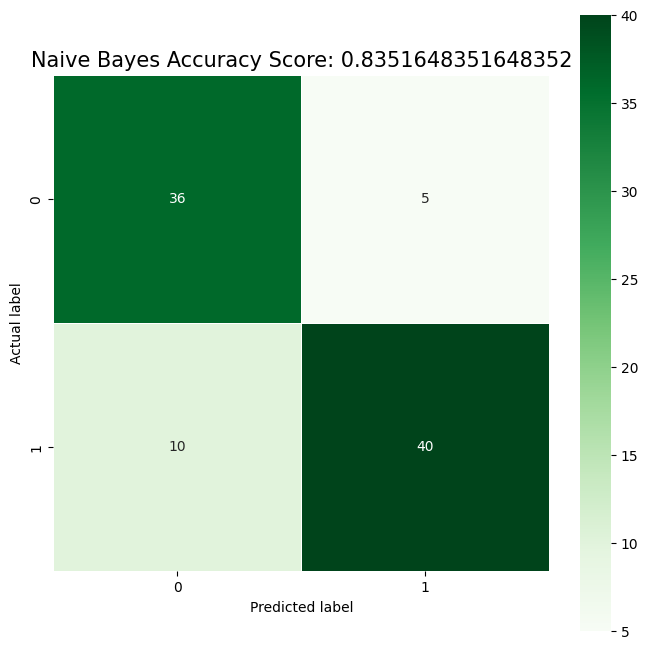

In [9]:
print("Lê Anh Pha - 6451071056")

gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred, zero_division=0))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Naive Bayes Accuracy Score: {0}'.format(bayes_score), size=15)
plt.show()

Câu 10: So sánh các mô hình

In [10]:
print("Lê Anh Pha - 6451071056")

preds = {'ID3 (entropy)': tree_pred, 'CART (gini)': cart_pred, 'Naive Bayes': bayes_pred}
summary = pd.DataFrame({
    'Mô hình': list(preds.keys()),
    'Accuracy': [metrics.accuracy_score(y_test, p) for p in preds.values()],
    'Precision (target=1)': [metrics.precision_score(y_test, p, pos_label=1, zero_division=0) for p in preds.values()],
    'Recall (target=1)': [metrics.recall_score(y_test, p, pos_label=1, zero_division=0) for p in preds.values()],
    'F1 (target=1)': [metrics.f1_score(y_test, p, pos_label=1, zero_division=0) for p in preds.values()],
})
summary

Lê Anh Pha - 6451071056


,Mô hình,Accuracy,Precision (target=1),Recall (target=1),F1 (target=1)
0,ID3 (entropy),0.725275,0.777778,0.7,0.736842
1,CART (gini),0.725275,0.777778,0.7,0.736842
2,Naive Bayes,0.835165,0.888889,0.8,0.842105
